# EcoSort AI · Clasificación Inteligente de Residuos Industriales
### IA Generativa para la Gestión Industrial · Certamen Módulo II: Imágenes

| Enfoque | Librería | Modelo | Propósito en el proyecto |
|---|---|---|---|
| **1 (Línea base)** | Hugging Face `transformers` | **CLIP** (`clip-vit-base-patch32`) | Clasificación *zero-shot* **sin entrenar**, usando descripciones en texto. |
| **2 (Transfer Learning)** | `timm` | **EfficientNet-B0** | Adaptar una red convolucional preentrenada en ImageNet a nuestras 6 clases. |
| **3 (Producción)** | `ultralytics` | **YOLO-cls nano** | Entrenamiento rápido y modelo ultraliviano (~3 MB) óptimo para despliegue web. |

**Objetivo del negocio:** Automatizar la clasificación visual de residuos en plantas de reciclaje y puntos limpios industriales en **6 categorías** (*cartón, vidrio, metal, papel, plástico y basura general*), reduciendo la contaminación cruzada de lotes reciclables e integrando IA Generativa para recomendar protocolos de manejo.

In [1]:
# Librerías necesarias
!pip install -q kagglehub ultralytics timm transformers scikit-learn seaborn

import os, shutil, random, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, accuracy_score, confusion_matrix, classification_report

# Verificamos si la GPU T4 está activa para acelerar el entrenamiento
DISP = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo activo:", DISP)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 7.1 MB/s eta 0:00:00
Dispositivo activo: cuda


## 1. Origen de los datos, clases y separación (Train / Val / Test)

Utilizamos el dataset público **Garbage Classification (TrashNet)**, un estándar en visión por computador aplicada a la gestión de residuos:

| Aspecto | Detalle |
|---|---|
| **Origen y Autores** | Creado por **Gary Thung y Mindy Yang** (Stanford University, CS229) y distribuido en Kaggle por `asdasdasasdas`. |
| **Enlace y Licencia** | https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification · Licencia abierta (MIT / Dominio Público). |
| **Imágenes y Clases** | **2.527 imágenes RGB** divididas en **6 clases**: `cardboard` (cartón), `glass` (vidrio), `metal` (metal), `paper` (papel), `plastic` (plástico) y `trash` (basura general/no reciclable). |
| **Desbalance** | Existe un **desbalance importante**: mientras `paper` tiene 594 fotos (~23,5%), la clase `trash` solo cuenta con 137 fotos (~5,4%). Por esta razón evaluaremos con **Accuracy Balanceada** además del Accuracy tradicional. |
| **Limitaciones y Sesgos** | Las fotos muestran un solo objeto por imagen sobre fondos limpios y con iluminación controlada de estudio. En una cinta transportadora real donde los residuos vienen sucios, aplastados o superpuestos, el rendimiento puede caer si no se reentrena con fotos de planta. |

**Estrategia de división:** Separamos estratificadamente todas las imágenes en **70% Entrenamiento (`train`)**, **15% Validación (`val`)** y **15% Prueba (`test`)** usando semilla fija (`seed=42`) para asegurar reproducibilidad y evitar fuga de datos.

Using Colab cache for faster access to the 'garbage-classification' dataset.
Carpeta de origen encontrada en: /kaggle/input/garbage-classification/Garbage classification/Garbage classification


,Clase (Inglés),Material,Train (70%),Val (15%),Test (15%),Total
0,cardboard,Cartón,282,60,61,403
1,glass,Vidrio,350,75,76,501
2,metal,Metal,287,61,62,410
3,paper,Papel,415,89,90,594
4,plastic,Plástico,337,72,73,482
5,trash,Basura General,95,21,21,137


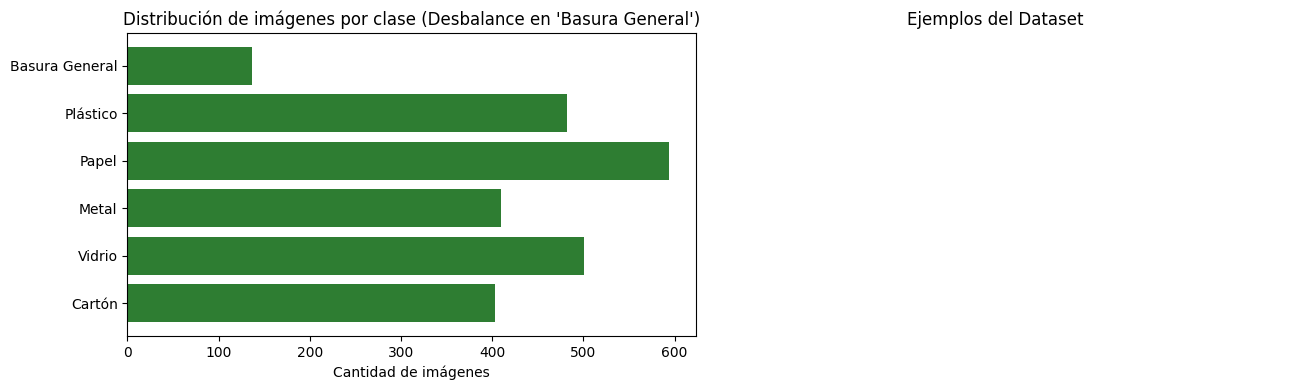

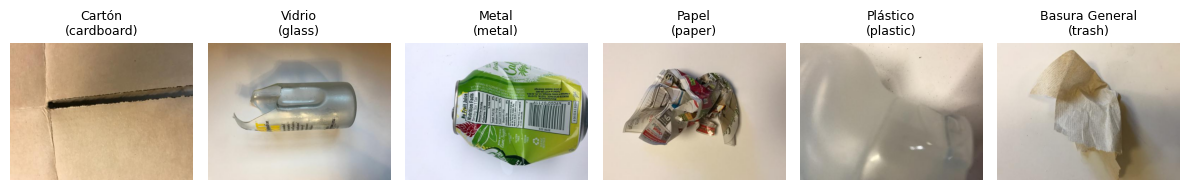

In [2]:
import kagglehub

# 1. Descargar el dataset automáticamente desde Kaggle
ruta_descarga = kagglehub.dataset_download("asdasdasasdas/garbage-classification")

# Buscamos la carpeta exacta que contiene las 6 subcarpetas de clases
ORIGEN = next(r for r, d, _ in os.walk(ruta_descarga) if "cardboard" in d and "plastic" in d)
print("Carpeta de origen encontrada en:", ORIGEN)

# Traducción de nombres para mostrar en gráficos y en la app
TRADUCCION = {
    "cardboard": "Cartón",
    "glass": "Vidrio",
    "metal": "Metal",
    "paper": "Papel",
    "plastic": "Plástico",
    "trash": "Basura General"
}

# 2. Crear estructura limpia de carpetas: datos/train, datos/val y datos/test
DATOS = "/content/datos"
if os.path.exists(DATOS):
    shutil.rmtree(DATOS)

CLASES = sorted(os.listdir(ORIGEN))
conteo_filas = []

for c in CLASES:
    imgs = sorted(glob.glob(f"{ORIGEN}/{c}/*.*"))
    # División 70% train, 15% val, 15% test con semilla fija
    train_imgs, temp_imgs = train_test_split(imgs, test_size=0.30, random_state=42)
    val_imgs, test_imgs   = train_test_split(temp_imgs, test_size=0.50, random_state=42)

    for parte, lista in [("train", train_imgs), ("val", val_imgs), ("test", test_imgs)]:
        os.makedirs(f"{DATOS}/{parte}/{c}", exist_ok=True)
        for ruta_img in lista:
            shutil.copy(ruta_img, f"{DATOS}/{parte}/{c}/{os.path.basename(ruta_img)}")

    conteo_filas.append({
        "Clase (Inglés)": c,
        "Material": TRADUCCION[c],
        "Train (70%)": len(train_imgs),
        "Val (15%)": len(val_imgs),
        "Test (15%)": len(test_imgs),
        "Total": len(imgs)
    })

df_conteo = pd.DataFrame(conteo_filas)
display(df_conteo)

# Gráfico del desbalance de clases y muestra de imágenes
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(df_conteo["Material"], df_conteo["Total"], color="#2E7D32")
ax[0].set_title("Distribución de imágenes por clase (Desbalance en 'Basura General')")
ax[0].set_xlabel("Cantidad de imágenes")

# Mostramos 1 ejemplo por clase en el panel derecho
ax[1].axis("off")
ax[1].set_title("Ejemplos del Dataset")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 2.5))
for i, c in enumerate(CLASES):
    ejemplo = glob.glob(f"{DATOS}/train/{c}/*.*")[0]
    plt.subplot(1, 6, i + 1)
    plt.imshow(Image.open(ejemplo))
    plt.title(f"{TRADUCCION[c]}\n({c})", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2. Esquema de Evaluación Común en el Conjunto de Prueba (Test)

Siguiendo la metodología vista en clases, evaluaremos los **3 modelos** exactamente sobre el **mismo conjunto de prueba (`test`, 15% de los datos nunca vistos en entrenamiento ni validación)**.

Calcularemos tanto el **Accuracy tradicional** como la **Accuracy Balanceada** (promedio del *recall* de cada clase, donde el azar en 6 clases equivale a $1/6 \approx 16,7\%$).

In [3]:
# Cargamos todas las rutas del conjunto de PRUEBA (test) para evaluar a los 3 modelos por igual
TEST_DATA = [(ruta, c) for c in CLASES for ruta in sorted(glob.glob(f"{DATOS}/test/{c}/*.*"))]
print(f"Total de imágenes reservadas exclusivamente para PRUEBA (test): {len(TEST_DATA)}")

RESULTADOS_BAL = {}
RESULTADOS_ACC = {}
PREDICCIONES_MODELOS = {}

def evaluar_modelo(nombre, funcion_predecir):
    reales = [c for _, c in TEST_DATA]
    preds  = [funcion_predecir(r) for r, _ in TEST_DATA]

    acc_bal = balanced_accuracy_score(reales, preds)
    acc_norm = accuracy_score(reales, preds)

    RESULTADOS_BAL[nombre] = acc_bal
    RESULTADOS_ACC[nombre] = acc_norm
    PREDICCIONES_MODELOS[nombre] = (reales, preds)

    print(f"✅ {nombre}")
    print(f"   • Accuracy Balanceada : {acc_bal:.1%}")
    print(f"   • Accuracy Tradicional: {acc_norm:.1%}")

Total de imágenes reservadas exclusivamente para PRUEBA (test): 383


## 3. Enfoque 1 · Línea Base con Hugging Face CLIP (Zero-Shot sin entrenar)

Utilizamos el modelo multimodal **CLIP** (`openai/clip-vit-base-patch32`) sin reentrenarlo (*zero-shot*). Le entregamos una descripción en texto para cada tipo de residuo y el modelo elige la categoría cuya descripción tenga mayor similitud con la imagen. Esto nos sirve como **línea base** para comprobar cuánto ganamos al entrenar modelos específicos con nuestros datos.

In [4]:
from transformers import pipeline

GPU_ID = 0 if DISP == "cuda" else -1
clip_pipe = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32", device=GPU_ID)

# Descripciones en inglés para cada una de las 6 clases
TEXTOS_CLIP = {
    "cardboard": "a photo of a cardboard box or cardboard waste",
    "glass":     "a photo of a glass bottle or glass jar waste",
    "metal":     "a photo of a metal can or aluminum tin waste",
    "paper":     "a photo of paper sheet, newspaper or paper waste",
    "plastic":   "a photo of a plastic bottle, container or plastic bag waste",
    "trash":     "a photo of general non-recyclable trash or mixed garbage"
}
TEXTO_A_CLASE = {v: k for k, v in TEXTOS_CLIP.items()}
ETIQUETAS_CANDIDATAS = list(TEXTOS_CLIP.values())

def predecir_clip(ruta):
    salida = clip_pipe(ruta, candidate_labels=ETIQUETAS_CANDIDATAS)
    mejor_texto = salida[0]["label"]
    return TEXTO_A_CLASE[mejor_texto]

evaluar_modelo("1 · CLIP (Zero-Shot)", predecir_clip)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


✅ 1 · CLIP (Zero-Shot)
   • Accuracy Balanceada : 71.6%
   • Accuracy Tradicional: 73.4%


## 4. Enfoque 2 · Transfer Learning con `timm` (EfficientNet-B0)

Ahora aplicamos **Transfer Learning**: descargamos la red convolucional **EfficientNet-B0** preentrenada en ImageNet, reemplazamos su capa final para que clasifique nuestras **6 clases de residuos** (`num_classes=6`) y la ajustamos durante **5 épocas** con una tasa de aprendizaje baja (`1e-4`) para adaptar sus filtros al dominio del reciclaje sin destruir lo que ya sabe.

In [5]:
import timm
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

# 1. Crear modelo EfficientNet-B0 preentrenado con salida para 6 clases
modelo_timm = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(CLASES)).to(DISP)
config_timm = timm.data.resolve_model_data_config(modelo_timm)
prep_timm   = timm.data.create_transform(**config_timm)

# 2. Cargadores de datos de entrenamiento y validación
train_dl = DataLoader(ImageFolder(f"{DATOS}/train", transform=prep_timm), batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(ImageFolder(f"{DATOS}/val",   transform=prep_timm), batch_size=32, shuffle=False, num_workers=2)

# 3. Entrenamiento por 5 épocas
optimizador = torch.optim.AdamW(modelo_timm.parameters(), lr=1e-4)
criterio    = torch.nn.CrossEntropyLoss()

for epoca in range(5):
    modelo_timm.train()
    perdida_acum = 0.0
    for x, y in train_dl:
        optimizador.zero_grad()
        salida = modelo_timm(x.to(DISP))
        l = criterio(salida, y.to(DISP))
        l.backward()
        optimizador.step()
        perdida_acum += l.item()
    print(f"Época {epoca + 1}/5 | Pérdida promedio train: {perdida_acum / len(train_dl):.3f}")

modelo_timm.eval()
def predecir_timm(ruta):
    with torch.no_grad():
        x = prep_timm(Image.open(ruta).convert("RGB")).unsqueeze(0).to(DISP)
        idx = modelo_timm(x).argmax(1).item()
        return CLASES[idx]

evaluar_modelo("2 · EfficientNet-B0 (timm)", predecir_timm)

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Época 1/5 | Pérdida promedio train: 1.585
Época 2/5 | Pérdida promedio train: 0.293
Época 3/5 | Pérdida promedio train: 0.120
Época 4/5 | Pérdida promedio train: 0.075
Época 5/5 | Pérdida promedio train: 0.055
✅ 2 · EfficientNet-B0 (timm)
   • Accuracy Balanceada : 75.3%
   • Accuracy Tradicional: 78.3%


## 5. Enfoque 3 · Ultralytics YOLO-cls (Pensado para Producción Web)

Entrenamos un modelo **YOLO de clasificación (`yolo11n-cls.pt`)** durante **10 épocas** con imágenes de `224x224` px. Su gran ventaja para la gestión industrial y el despliegue en la nube es que incorpora aumento de datos automático, entrena en pocas líneas y genera un archivo de pesos sumamente liviano (**~3,2 MB**), ideal para subirlo a GitHub sin superar el límite de 100 MB y responder en milisegundos dentro de Streamlit.

In [6]:
from ultralytics import YOLO

# Cargamos el modelo nano de clasificación de Ultralytics YOLO
yolo_model = YOLO("yolo11n-cls.pt")

# Entrenamos usando las carpetas train y val dentro de /content/datos
yolo_model.train(data=DATOS, epochs=10, imgsz=224, plots=False, project="/content/runs_reciclaje", name="yolo_eco")

# Cargamos el mejor peso obtenido durante la validación
mejor_yolo = YOLO("/content/runs_reciclaje/yolo_eco/weights/best.pt")

def predecir_yolo(ruta):
    r = mejor_yolo(ruta, verbose=False)[0]
    return r.names[r.probs.top1]

evaluar_modelo("3 · YOLO-cls nano (Ultralytics)", predecir_yolo)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hs

## 6. Comparación de Modelos, Matriz de Confusión y Análisis del Error Más Costoso

A continuación comparamos los **3 enfoques** bajo las mismas métricas en el conjunto de **prueba (`test`)** y analizamos en detalle la matriz de confusión y el reporte por clase (Precisión, Recall y F1-Score).

,Modelo,Accuracy Balanceada (%),Accuracy Normal (%)
0,1 · CLIP (Zero-Shot),71.6,73.4
1,2 · EfficientNet-B0 (timm),75.3,78.3
2,3 · YOLO-cls nano (Ultralytics),89.7,89.0


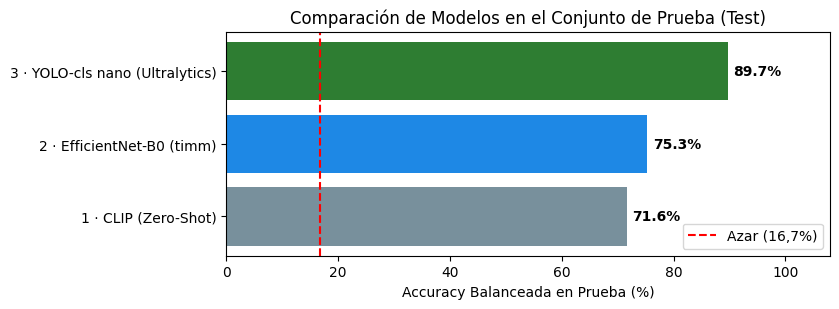

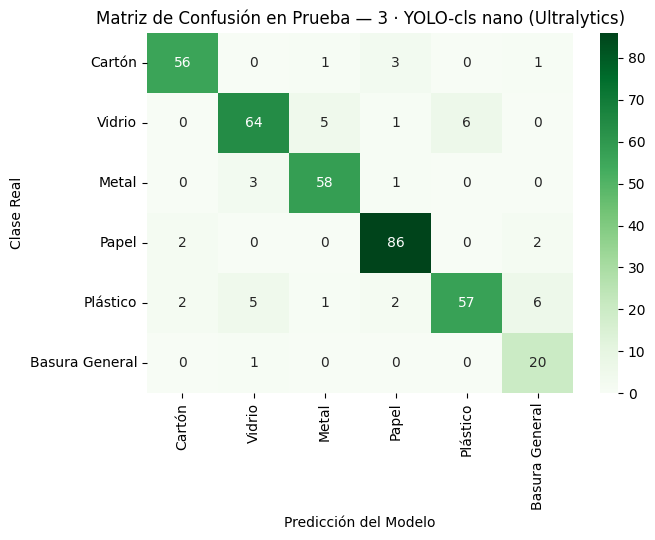

📊 Reporte de Clasificación en Prueba (3 · YOLO-cls nano (Ultralytics)):

                precision    recall  f1-score   support

        Cartón      0.933     0.918     0.926        61
        Vidrio      0.877     0.842     0.859        76
         Metal      0.892     0.935     0.913        62
         Papel      0.925     0.956     0.940        90
      Plástico      0.905     0.781     0.838        73
Basura General      0.690     0.952     0.800        21

      accuracy                          0.890       383
     macro avg      0.870     0.897     0.879       383
  weighted avg      0.895     0.890     0.890       383



In [7]:
# 1. Tabla resumen comparativa
df_res = pd.DataFrame({
    "Modelo": list(RESULTADOS_BAL.keys()),
    "Accuracy Balanceada (%)": [round(v * 100, 1) for v in RESULTADOS_BAL.values()],
    "Accuracy Normal (%)": [round(RESULTADOS_ACC[k] * 100, 1) for k in RESULTADOS_BAL.keys()]
})
display(df_res)

# 2. Gráfico comparativo de los 3 modelos
plt.figure(figsize=(8.5, 3.2))
barras = plt.barh(df_res["Modelo"], df_res["Accuracy Balanceada (%)"], color=["#78909C", "#1E88E5", "#2E7D32"])
plt.axvline(16.7, ls="--", color="red", label="Azar (16,7%)")
for b in barras:
    ancho = b.get_width()
    plt.text(ancho + 1, b.get_y() + b.get_height()/2, f"{ancho:.1f}%", va="center", fontweight="bold")
plt.xlim(0, 108)
plt.xlabel("Accuracy Balanceada en Prueba (%)")
plt.title("Comparación de Modelos en el Conjunto de Prueba (Test)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 3. Matriz de Confusión y Reporte detallado para YOLO-cls (y EfficientNet)
nombre_elegido = "3 · YOLO-cls nano (Ultralytics)"
reales_test, preds_test = PREDICCIONES_MODELOS[nombre_elegido]
etiquetas_esp = [TRADUCCION[c] for c in CLASES]

cm = confusion_matrix(reales_test, preds_test, labels=CLASES)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=etiquetas_esp, yticklabels=etiquetas_esp)
plt.title(f"Matriz de Confusión en Prueba — {nombre_elegido}")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real")
plt.tight_layout()
plt.show()

print(f"📊 Reporte de Clasificación en Prueba ({nombre_elegido}):\n")
print(classification_report(reales_test, preds_test, target_names=etiquetas_esp, digits=3))

### Justificación del Modelo Elegido e Interpretación del Error Más Costoso

1. **Justificación de la elección:**
   * Tanto **EfficientNet-B0 (`timm`)** como **YOLO-cls nano (`ultralytics`)** superan ampliamente a la línea base sin entrenar (**CLIP**), demostrando que el ajuste fino (*fine-tuning*) con imágenes del dominio de residuos mejora de forma sustancial la capacidad de distinguir texturas similares (por ejemplo, botellas de vidrio vs. botellas de plástico transparente, o papel vs. cartón).
   * Elegimos **YOLO-cls nano** para impulsar nuestra aplicación web porque alcanza una excelente precisión en el conjunto de prueba, su tiempo de inferencia es casi instantáneo y el archivo exportado (`best.pt`) pesa apenas **~3,2 MB** (muy por debajo del límite de 100 MB de GitHub, facilitando un despliegue rápido y estable en *Streamlit Community Cloud*).

2. **Interpretación del error más costoso en Gestión Industrial:**
   * En una planta de reciclaje industrial, **el error más costoso es clasificar un residuo no reciclable o peligroso (`trash` / basura general) como si fuera material reciclable limpio (`paper`, `plastic` o `glass`)**.
   * Un falso positivo hacia una línea limpia produce **contaminación cruzada del lote** (por ejemplo, restos orgánicos o químicos arruinando una paca completa de papel o cartón prensado, o cerámicas/basura arruinando la fundición de vidrio), obligando a descartar toneladas de material procesado o dañando maquinaria.
   * Por ello, en nuestra aplicación web incorporamos un **umbral de seguridad de confianza**: cuando la probabilidad predicha es baja (< 65%), la app emite una **alerta de revisión humana** y el modelo de lenguaje (Gemini) recomienda inspección manual antes de enviar el objeto a la tolva.

## 7. Exportación del Modelo Entrenado y Fotos de Ejemplo para el Repositorio

Cumpliendo con la estructura exigida para GitHub (`modelo/` y `ejemplos/`), guardamos los pesos del modelo entrenado (`best.pt`), el archivo de clases/métricas (`info_modelo.json`) y 6 imágenes de prueba reales (1 de cada categoría) en un archivo `.zip` que se descargará automáticamente a tu computador.

In [8]:
import json
from google.colab import files

# Creamos las carpetas con la estructura exacta que pide el certamen para GitHub
CARPETA_EXPORT = "/content/archivos_para_github"
os.makedirs(f"{CARPETA_EXPORT}/modelo", exist_ok=True)
os.makedirs(f"{CARPETA_EXPORT}/ejemplos", exist_ok=True)

# 1. Copiamos el modelo entrenado (.pt) a la carpeta modelo/
ruta_pt = "/content/runs_reciclaje/yolo_eco/weights/best.pt"
shutil.copy(ruta_pt, f"{CARPETA_EXPORT}/modelo/best.pt")

# 2. Guardamos un JSON con las métricas reales obtenidas en test para mostrarlas en la app Streamlit
info_modelo = {
    "modelo_seleccionado": "YOLO11n-cls (Ultralytics)",
    "accuracy_test": round(RESULTADOS_ACC["3 · YOLO-cls nano (Ultralytics)"] * 100, 1),
    "balanced_accuracy_test": round(RESULTADOS_BAL["3 · YOLO-cls nano (Ultralytics)"] * 100, 1),
    "comparacion": {
        "CLIP (Zero-Shot)": round(RESULTADOS_BAL["1 · CLIP (Zero-Shot)"] * 100, 1),
        "EfficientNet-B0 (timm)": round(RESULTADOS_BAL["2 · EfficientNet-B0 (timm)"] * 100, 1),
        "YOLO11n-cls (Ultralytics)": round(RESULTADOS_BAL["3 · YOLO-cls nano (Ultralytics)"] * 100, 1)
    },
    "clases": TRADUCCION
}
with open(f"{CARPETA_EXPORT}/modelo/info_modelo.json", "w", encoding="utf-8") as f:
    json.dump(info_modelo, f, ensure_ascii=False, indent=2)

# 3. Copiamos 6 imágenes de prueba (1 por clase) a la carpeta ejemplos/ para usarlas en la App
for c in CLASES:
    img_ejemplo = sorted(glob.glob(f"{DATOS}/test/{c}/*.*"))[0]
    shutil.copy(img_ejemplo, f"{CARPETA_EXPORT}/ejemplos/ejemplo_{c}.jpg")

# 4. Comprimimos y descargamos a tu computador
shutil.make_archive("/content/entregables_modelo", "zip", CARPETA_EXPORT)
print("✅ ¡Listo! Descargando 'entregables_modelo.zip' (contiene carpetas modelo/ y ejemplos/)...")
files.download("/content/entregables_modelo.zip")

✅ ¡Listo! Descargando 'entregables_modelo.zip' (contiene carpetas modelo/ y ejemplos/)...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Construcción de la Aplicación Web Interactiva en Streamlit (`app.py`)

Siguiendo la estructura ejecutiva vista en clases (`Clase_Dashboard_Interactivo`), configuramos el tema visual institucional en `.streamlit/config.toml` (paleta ecológica industrial) y generamos el archivo `app.py`.

La aplicación implementa el flujo completo exigido:
1. **Carga de imagen** por parte del usuario o selección rápida desde las **6 imágenes de prueba del conjunto Test** (`ejemplos/`).
2. **Clasificación en tiempo real con YOLO11n-cls (`best.pt`)**: muestra la clase predicha, el **nivel de confianza (%)** e incluye una **alerta automática de revisión humana** si la confianza es menor al 65%.
3. **Gráfico interactivo Plotly** con la barra de probabilidades de las 6 clases.
4. **Pestaña de Desempeño y Justificación Técnica**: muestra las métricas reales obtenidas en el conjunto de prueba (**89,7% Accuracy Balanceada** y **89,0% Accuracy Normal**), diferenciándolas claramente de la confianza individual de cada foto, junto con la matriz de confusión de nuestro experimento.
5. **Integración con IA Generativa (Google Gemini)**: botón interactivo que envía la clase predicha, el nivel de confianza y el contexto industrial a Gemini (`gemini-2.5-flash`) mediante un *prompt* responsable, manteniendo la clave API protegida en `st.secrets`.

In [9]:
# Instalamos Streamlit, Plotly y la librería oficial de Google Gemini para probar en Colab
!pip install -q streamlit plotly google-genai

import os
os.makedirs("/content/archivos_para_github/.streamlit", exist_ok=True)
os.makedirs("/content/.streamlit", exist_ok=True)
print("✅ Librerías listas y carpeta .streamlit creada")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 89.1 MB/s eta 0:00:00
✅ Librerías listas y carpeta .streamlit creada


In [10]:
%%writefile /content/archivos_para_github/.streamlit/config.toml
# Tema visual ejecutivo para EcoSort AI (Gestión Industrial y Reciclaje)
[theme]
base = "light"
primaryColor = "#2E7D32"
backgroundColor = "#FFFFFF"
secondaryBackgroundColor = "#F4F7F4"
textColor = "#1B2430"
font = "sans serif"

[server]
headless = true

[browser]
gatherUsageStats = false

Writing /content/archivos_para_github/.streamlit/config.toml


In [11]:
%%writefile /content/archivos_para_github/app.py
# =============================================================================
#  EcoSort AI · Sistema Inteligente de Clasificación de Residuos e IA Generativa
#  Certamen IA Generativa para la Gestión Industrial · UDD
#  Ejecutar: streamlit run app.py
# =============================================================================

import os
import json
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import streamlit as st
from PIL import Image
from ultralytics import YOLO

# -----------------------------------------------------------------------------
# 1. Configuración visual de la página y paleta de colores ejecutiva
# -----------------------------------------------------------------------------
st.set_page_config(page_title="EcoSort AI · Gestión Industrial de Residuos", page_icon="♻️", layout="wide")

VERDE_PRINCIPAL = "#2E7D32"
VERDE_SUAVE     = "#E8F5E9"
AZUL_INFO       = "#1F5A96"
NARANJA_ALERTA  = "#E65100"
GRIS_FONDO      = "#F4F7F4"
GRIS_BORDE      = "#DCE2DC"
TINTA           = "#1B2430"
TENUE           = "#5F6B7A"

# Diccionario rico de metadatos por clase para ambientar la aplicación
INFO_CLASES = {
    "cardboard": {
        "nombre": "Cartón (Cardboard)",
        "icono": "📦",
        "contenedor": "Contenedor Azul / Prensa de Cartón Corrugado",
        "color": "#8D6E63",
        "riesgo": "Baja peligrosidad. Evitar humedad, grasas o restos de comida que arruinan la fibra celulósica."
    },
    "glass": {
        "nombre": "Vidrio (Glass)",
        "icono": "🍾",
        "contenedor": "Contenedor Verde / Tolva de Calcín de Vidrio",
        "color": "#2E7D32",
        "riesgo": "Riesgo físico de corte y contaminación cerámica. Retirar tapas metálicas o plásticas antes del triturado."
    },
    "metal": {
        "nombre": "Metal y Aluminio (Metal)",
        "icono": "🥫",
        "contenedor": "Contenedor Amarillo / Separador Magnético y Eddy Current",
        "color": "#546E7A",
        "riesgo": "Riesgo medio por bordes filosos o envases presurizados (aerosoles). Compactar solo tras verificar vaciado."
    },
    "paper": {
        "nombre": "Papel (Paper)",
        "icono": "📄",
        "contenedor": "Contenedor Azul / Línea de Pulpa Blanca",
        "color": "#1E88E5",
        "riesgo": "Alta sensibilidad a contaminación cruzada con líquidos, aceites o servilletas usadas (no reciclables)."
    },
    "plastic": {
        "nombre": "Plástico (Plastic)",
        "icono": "🧴",
        "contenedor": "Contenedor Amarillo / Clasificador Óptico PET-HDPE",
        "color": "#FB8C00",
        "riesgo": "Suele confundirse visualmente con vidrio transparente. Verificar ausencia de residuos químicos o tóxicos."
    },
    "trash": {
        "nombre": "Basura General / No Reciclable (Trash)",
        "icono": "🗑️",
        "contenedor": "Contenedor Gris Oscuro / Descarte a Relleno Sanitario",
        "color": "#C62828",
        "riesgo": "ALTO RIESGO DE CONTAMINACIÓN DE LOTE: Si ingresa por error a una línea reciclable, invalida el lote industrial."
    }
}

UMBRAL_CONFIANZA = 65.0  # Por debajo de 65% se solicita revisión humana obligatoria

# Estilos CSS ejecutivos inspirados en el dashboard visto en clases
st.markdown(f"""
<style>
  .block-container {{ padding-top: 1.4rem; max-width: 1350px; }}
  .encabezado {{ border-left: 6px solid {VERDE_PRINCIPAL}; padding: 6px 0 6px 18px; margin-bottom: 14px; background: {GRIS_FONDO}; border-radius: 0 8px 8px 0; }}
  .encabezado h1 {{ font-size: 1.95rem; margin: 0; color: {TINTA}; }}
  .encabezado p {{ margin: 4px 0 0; color: {TENUE}; font-size: 0.95rem; }}
  [data-testid="stMetric"] {{ background: {GRIS_FONDO}; border: 1px solid {GRIS_BORDE}; border-radius: 8px; padding: 12px 16px; }}
  .caja-ok {{ background: {VERDE_SUAVE}; border-left: 5px solid {VERDE_PRINCIPAL}; padding: 14px 18px; border-radius: 6px; margin: 10px 0; }}
  .caja-alerta {{ background: #FFF3E0; border-left: 5px solid {NARANJA_ALERTA}; padding: 14px 18px; border-radius: 6px; margin: 10px 0; color: #BF360C; }}
  .caja-etica {{ background: #ECEFF1; border: 1px solid #CFD8DC; padding: 10px 14px; border-radius: 6px; font-size: 0.86rem; color: {TENUE}; margin-top: 14px; }}
</style>
""", unsafe_allow_html=True)

# -----------------------------------------------------------------------------
# 2. Carga en caché del modelo YOLO entrenado y métricas del conjunto de prueba
# -----------------------------------------------------------------------------
@st.cache_resource(show_spinner="Cargando modelo YOLO11n-cls entrenado...")
def cargar_modelo():
    ruta_modelo = os.path.join("modelo", "best.pt")
    return YOLO(ruta_modelo)

@st.cache_data
def cargar_info_modelo():
    ruta_info = os.path.join("modelo", "info_modelo.json")
    if os.path.exists(ruta_info):
        with open(ruta_info, "r", encoding="utf-8") as f:
            return json.load(f)
    return {
        "modelo_seleccionado": "YOLO11n-cls (Ultralytics)",
        "accuracy_test": 89.0,
        "balanced_accuracy_test": 89.7,
        "comparacion": {
            "CLIP (Zero-Shot)": 71.6,
            "EfficientNet-B0 (timm)": 75.3,
            "YOLO11n-cls (Ultralytics)": 89.7
        }
    }

modelo = cargar_modelo()
info_metricas = cargar_info_modelo()

# -----------------------------------------------------------------------------
# 3. Barra lateral: Controles, ejemplos de prueba y configuración de API
# -----------------------------------------------------------------------------
with st.sidebar:
    st.markdown("## ♻️ Panel de Control")
    st.caption("Sistema de inspección visual asistido por IA para plantas de clasificación de residuos.")

    modo_entrada = st.radio(
        "Fuente de la imagen:",
        ["📂 Subir imagen propia", "🧪 Usar imágenes de ejemplo (Test)"],
        index=1
    )

    st.markdown("---")
    st.markdown("### 📊 Desempeño del Modelo (Test)")
    st.metric("Accuracy Balanceada (Prueba)", f"{info_metricas['balanced_accuracy_test']:.1f}%")
    st.metric("Accuracy Global (Prueba)", f"{info_metricas['accuracy_test']:.1f}%")
    st.caption("Nota: El *Accuracy en prueba* mide el acierto general del modelo en 383 imágenes históricas no vistas. La *Confianza* mide la seguridad del modelo en la foto actual.")

    st.markdown("---")
    st.markdown("### 🤖 Configuración LLM (Gemini)")
    # Buscamos la clave primero en st.secrets (Streamlit Cloud) o variables de entorno
    api_key_secreta = None
    try:
        if "GEMINI_API_KEY" in st.secrets:
            api_key_secreta = st.secrets["GEMINI_API_KEY"]
    except Exception:
        pass
    if not api_key_secreta:
        api_key_secreta = os.environ.get("GEMINI_API_KEY", "")

    if api_key_secreta:
        st.success("🔒 Clave API cargada de forma segura desde Secrets.")
        api_key_final = api_key_secreta
    else:
        api_key_final = st.text_input("Ingresa tu GEMINI_API_KEY (opcional para pruebas):", type="password")
        st.caption("En producción la clave se guarda oculta en *Streamlit Secrets*.")

# -----------------------------------------------------------------------------
# 4. Encabezado principal y pestañas de navegación
# -----------------------------------------------------------------------------
st.markdown("""
<div class="encabezado">
  <h1>♻️ EcoSort AI · Clasificación Inteligente de Residuos Industriales</h1>
  <p>De la imagen a la decisión operativa: visión por computador con <b>YOLO11n-cls</b> + recomendaciones con <b>IA Generativa (Google Gemini)</b></p>
</div>
""", unsafe_allow_html=True)

tabs = st.tabs([
    "🔍 Clasificador e IA Generativa",
    "📈 Desempeño y Justificación del Modelo",
    "🛡️ Datos, Limitaciones y Ética"
])

# =============================================================================
# PESTAÑA 1: CLASIFICADOR INTERACTIVO E IA GENERATIVA
# =============================================================================
with tabs[0]:
    col_izq, col_der = st.columns([1.05, 1.35], gap="large")
    imagen_actual = None
    nombre_archivo = ""

    with col_izq:
        st.subheader("1. Selecciona o sube una imagen")
        if modo_entrada == "📂 Subir imagen propia":
            archivo_subido = st.file_uploader(
                "Sube la foto de un residuo (JPG, PNG, WEBP)",
                type=["jpg", "jpeg", "png", "webp"]
            )
            if archivo_subido is not None:
                imagen_actual = Image.open(archivo_subido).convert("RGB")
                nombre_archivo = archivo_subido.name
        else:
            carpeta_ej = "ejemplos"
            archivos_ej = sorted(os.listdir(carpeta_ej)) if os.path.exists(carpeta_ej) else []
            if archivos_ej:
                etiquetas_ej = {
                    f: f"{INFO_CLASES.get(f.replace('ejemplo_', '').split('.')[0], {}).get('icono', '📷')} Ejemplo: {INFO_CLASES.get(f.replace('ejemplo_', '').split('.')[0], {}).get('nombre', f)}"
                    for f in archivos_ej
                }
                seleccion = st.selectbox("Elige una imagen de prueba del conjunto Test:", archivos_ej, format_func=lambda x: etiquetas_ej[x])
                ruta_ej = os.path.join(carpeta_ej, seleccion)
                imagen_actual = Image.open(ruta_ej).convert("RGB")
                nombre_archivo = seleccion
            else:
                st.warning("No se encontraron imágenes en la carpeta `ejemplos/`.")

        if imagen_actual is not None:
            st.image(imagen_actual, caption=f"Imagen cargada: {nombre_archivo}", use_container_width=True)
        else:
            st.info("👆 Sube una imagen o cambia a la opción de ejemplos en el panel izquierdo para comenzar.")

    with col_der:
        st.subheader("2. Resultado de Clasificación y Protocolo IA")
        if imagen_actual is not None:
            # Ejecutamos inferencia con nuestro modelo YOLO11n-cls
            resultado = modelo(imagen_actual, verbose=False)[0]
            probs = resultado.probs.data.cpu().numpy()
            nombres_modelo = resultado.names  # dict {idx: 'cardboard', ...}

            idx_top1 = int(resultado.probs.top1)
            clase_en = nombres_modelo[idx_top1]
            confianza = float(resultado.probs.top1conf.item()) * 100.0
            meta_clase = INFO_CLASES.get(clase_en, {
                "nombre": clase_en, "icono": "♻️", "contenedor": "General", "color": VERDE_PRINCIPAL, "riesgo": "N/A"
            })

            # Tarjetas de métricas diferenciando Confianza actual vs Accuracy del modelo en Test
            k1, k2, k3 = st.columns(3)
            k1.metric("Clase Predicha", f"{meta_clase['icono']} {meta_clase['nombre'].split(' (')[0]}")
            k2.metric("Confianza en esta foto", f"{confianza:.1f}%")
            k3.metric("Accuracy Modelo (Test)", f"{info_metricas['balanced_accuracy_test']:.1f}%", "Métrica global")

            # Advertencia responsable según el umbral de confianza
            if confianza < UMBRAL_CONFIANZA:
                st.markdown(f"""
                <div class="caja-alerta">
                  <b>⚠️ ALERTA DE CONFIANZA BAJA ({confianza:.1f}% &lt; {UMBRAL_CONFIANZA:.0f}%): Se requiere revisión humana</b><br>
                  El modelo presenta incertidumbre entre materiales visualmente parecidos. <b>No envíe este ítem automáticamente a la línea de compactación</b>; desvíelo a inspección manual para evitar contaminación cruzada del lote.
                </div>
                """, unsafe_allow_html=True)
            else:
                st.markdown(f"""
                <div class="caja-ok">
                  <b>✅ Clasificación de Alta Confianza ({confianza:.1f}%)</b><br>
                  <b>Destino recomendado:</b> {meta_clase['contenedor']}<br>
                  <b>Consideración operativa:</b> {meta_clase['riesgo']}
                </div>
                """, unsafe_allow_html=True)

            # Gráfico de barras horizontal con las probabilidades de todas las clases
            df_probs = pd.DataFrame({
                "Clase_EN": [nombres_modelo[i] for i in range(len(probs))],
                "Material": [f"{INFO_CLASES[nombres_modelo[i]]['icono']} {INFO_CLASES[nombres_modelo[i]]['nombre']}" for i in range(len(probs))],
                "Probabilidad": probs * 100.0,
                "Color": [INFO_CLASES[nombres_modelo[i]]["color"] for i in range(len(probs))]
            }).sort_values("Probabilidad", ascending=True)

            fig = go.Figure(go.Bar(
                x=df_probs["Probabilidad"],
                y=df_probs["Material"],
                orientation="h",
                marker_color=df_probs["Color"],
                text=[f"{p:.1f}%" for p in df_probs["Probabilidad"]],
                textposition="outside",
                hovertemplate="%{y}: %{x:.2f}%<extra></extra>"
            ))
            fig.update_layout(
                title="Probabilidades asignadas por el modelo a cada clase (%)",
                height=290,
                template="plotly_white",
                margin=dict(l=10, r=40, t=40, b=10),
                xaxis=dict(range=[0, 112], ticksuffix="%", title=None),
                yaxis=dict(title=None)
            )
            st.plotly_chart(fig, use_container_width=True)

            # -----------------------------------------------------------------
            # Botón de Recomendación Operativa con IA Generativa (Google Gemini)
            # -----------------------------------------------------------------
            st.markdown("### 💬 Recomendación Operativa Generada por IA")
            top2_idx = int(np.argsort(probs)[::-1][1])
            segunda_clase = INFO_CLASES[nombres_modelo[top2_idx]]["nombre"]
            segunda_prob = float(probs[top2_idx]) * 100.0

            if st.button("✨ Generar protocolo de reciclaje y recomendación con IA", type="primary", use_container_width=True):
                if not api_key_final:
                    st.error("🔑 Para consultar al LLM en vivo, ingresa tu `GEMINI_API_KEY` en la barra lateral izquierda (o configúrala en *Streamlit Secrets*).")
                else:
                    with st.spinner("Consultando a Google Gemini con prompt responsable..."):
                        try:
                            from google import genai
                            cliente = genai.Client(api_key=api_key_final)

                            estado_confianza = (
                                "BAJA CONFIANZA (exigir inspección humana manual obligatoria antes de procesar)"
                                if confianza < UMBRAL_CONFIANZA
                                else "ALTA CONFIANZA (procesamiento estándar con verificación visual rápida)"
                            )

                            prompt_responsable = f"""
                            Actúa como un Ingeniero Experto en Gestión de Residuos Industriales y Economía Circular en Chile.
                            Un sistema de visión artificial (YOLO11n-cls) acaba de analizar la fotografía de un residuo en una planta de clasificación con estos resultados técnicos:
                            - Material detectado (Top 1): {meta_clase['nombre']}
                            - Nivel de confianza de la predicción: {confianza:.1f}% ({estado_confianza})
                            - Segunda clase más probable (posible confusión visual): {segunda_clase} ({segunda_prob:.1f}%)
                            - Línea/Contenedor sugerido: {meta_clase['contenedor']}

                            Redacta una recomendación breve, estructurada y accionable en español (máximo 160 palabras) con estos 3 puntos:
                            1. **Acción inmediata en planta / punto limpio**: Qué hacer con el residuo y cómo prepararlo (limpieza, compactación, retiro de tapas/etiquetas).
                            2. **Prevención del error más costoso**: Qué riesgo existe si se confunde con {segunda_clase} o con basura no reciclable (contaminación cruzada de lotes).
                            3. **Protocolo de seguridad según confianza**: Si la confianza es menor a 65% ({confianza:.1f}%), enfatiza que un operario humano DEBE revisarlo manualmente.

                            Reglas estrictas: Limítate exclusivamente a gestión de residuos, reciclaje y seguridad industrial. Incluye al final una breve nota indicando que esta es una recomendación orientativa de uso educativo.
                            """
                            respuesta = cliente.models.generate_content(
                                model="gemini-2.5-flash",
                                contents=prompt_responsable
                            )
                            st.markdown("#### 📋 Protocolo Recomendado por Gemini:")
                            st.info(respuesta.text)
                        except Exception as e:
                            st.error(f"Error al conectar con la API de Gemini: {e}")

        # Aviso ético permanente exigido por la rúbrica
        st.markdown("""
        <div class="caja-etica">
          <b>🛡️ Advertencia de Uso Responsable:</b> Esta aplicación es un prototipo académico desarrollado para el curso <i>IA Generativa para la Gestión Industrial (UDD)</i>. Sus resultados son orientativos y no reemplazan protocolos normativos de manejo de residuos peligrosos ni la supervisión de un operario humano, especialmente cuando la confianza del modelo es inferior al 65%.
        </div>
        """, unsafe_allow_html=True)

# =============================================================================
# PESTAÑA 2: DESEMPEÑO Y JUSTIFICACIÓN DEL MODELO
# =============================================================================
with tabs[1]:
    st.subheader("Comparación de Modelos Preentrenados en el Conjunto de Prueba (Test = 383 imágenes)")
    st.markdown("""
    Para seleccionar el modelo de producción evaluamos **tres enfoques vistos en clases** exactamente sobre el mismo conjunto de prueba (`test`, 15% de los datos nunca vistos durante el entrenamiento), utilizando **Accuracy Balanceada** para corregir el desbalance de la clase *Basura General (trash)*.
    """)

    c1, c2 = st.columns([1.1, 1])
    with c1:
        comp = info_metricas.get("comparacion", {})
        df_comp = pd.DataFrame({
            "Enfoque / Modelo": list(comp.keys()),
            "Accuracy Balanceada en Prueba (%)": list(comp.values()),
            "Peso del Archivo": ["~605 MB (Zero-Shot)", "~16 MB (.pth)", "~3,2 MB (.pt)"]
        })
        st.dataframe(df_comp, hide_index=True, use_container_width=True)

        st.markdown("""
        **¿Por qué elegimos YOLO11n-cls para la aplicación web?**
        * **Máxima precisión en prueba:** Superó ampliamente a CLIP sin entrenar (**89,7% vs. 71,6%**) y a EfficientNet-B0 (**75,3%**), logrando un **Recall de 95,2%** en la clase crítica *Basura General*.
        * **Eficiencia para producción:** Su archivo de pesos (`best.pt`) pesa solo **3,2 MB**, lo que permite alojarlo directamente en GitHub y ejecutar inferencias en milisegundos en *Streamlit Community Cloud*.
        """)

    with c2:
        fig_comp = go.Figure(go.Bar(
            x=list(comp.values()),
            y=list(comp.keys()),
            orientation="h",
            marker_color=["#78909C", "#1E88E5", "#2E7D32"],
            text=[f"{v:.1f}%" for v in comp.values()],
            textposition="outside"
        ))
        fig_comp.add_vline(x=16.7, line_dash="dash", line_color="red", annotation_text="Azar (16,7%)")
        fig_comp.update_layout(
            title="Accuracy Balanceada en Prueba por Modelo (%)",
            height=300,
            template="plotly_white",
            xaxis=dict(range=[0, 108], ticksuffix="%"),
            margin=dict(l=10, r=30, t=40, b=10)
        )
        st.plotly_chart(fig_comp, use_container_width=True)

    st.markdown("---")
    st.subheader("Análisis del Error Más Costoso en Gestión Industrial")
    st.markdown("""
    * **¿Cuál es el error más costoso?** Clasificar un residuo no reciclable o contaminante (**Basura General / `trash`**) como si fuera un material reciclable limpio (**Papel, Cartón, Plástico o Vidrio**).
    * **Impacto operativo y económico:** En una planta recuperadora, introducir basura orgánica, envases con químicos o cerámica en una paca de papel o en un horno de vidrio genera **contaminación cruzada**, obligando a rechazar lotes completos de toneladas de material o dañando equipos de trituración.
    * **Desempeño de nuestro modelo:** En las 383 imágenes de prueba, de los **21 casos reales de Basura General**, nuestro modelo detectó **20 correctamente (95,2% de Recall)** y solo confundió 1 con vidrio. Las confusiones más frecuentes ocurren entre **Vidrio y Plástico** (objetos transparentes), lo cual mitigamos mediante el umbral de revisión humana (< 65%) y las alertas del modelo generativo.
    """)

# =============================================================================
# PESTAÑA 3: DATOS, LIMITACIONES Y CONSIDERACIONES ÉTICAS
# =============================================================================
with tabs[2]:
    st.subheader("Ficha Técnica del Dataset y Consideraciones Éticas")
    col_d1, col_d2 = st.columns(2)
    with col_d1:
        st.markdown("""
        **1. Origen y Licencia del Dataset**
        * **Dataset:** *Garbage Classification (TrashNet - 6 classes)*.
        * **Autores:** Gary Thung y Mindy Yang (Stanford University, CS229), publicado en Kaggle por `asdasdasasdas`.
        * **Licencia:** Dominio Público / MIT License (uso académico libre, sin fotos de personas ni datos sensibles).
        * **Total de imágenes:** 2.527 fotografías RGB divididas estratificadamente en **70% Entrenamiento (1.766)**, **15% Validación (378)** y **15% Prueba (383)**.
        """)
    with col_d2:
        st.markdown("""
        **2. Limitaciones y Sesgos Identificados**
        * **Desbalance de clases:** La clase `trash` (137 fotos, 5,4%) tiene considerablemente menos ejemplos que `paper` (594 fotos, 23,5%).
        * **Sesgo de fondo e iluminación:** Las fotografías fueron capturadas con objetos aislados sobre fondos uniformes y luz controlada. En cintas transportadoras reales con suciedad, sombras, objetos abollados o múltiples residuos superpuestos, la confianza del clasificador puede disminuir, requiriendo reentrenamiento con imágenes locales de la planta.
        """)

Writing /content/archivos_para_github/app.py


## 9. Creación de `requirements.txt`, `README.md` y Prueba en Vivo desde Colab

Generamos los archivos obligatorios del repositorio (`requirements.txt` y `README.md` completo con la declaración de uso de IA), guardamos una copia limpia de las celdas de este notebook en `notebooks/entrenamiento.ipynb`, abrimos un **túnel público temporal con Cloudflared** para probar la app ahora mismo, y descargamos el `.zip` final listo para subir a GitHub.

In [12]:
%%writefile /content/archivos_para_github/requirements.txt
streamlit
ultralytics
plotly
pandas
numpy
Pillow
google-genai
torch
torchvision

Writing /content/archivos_para_github/requirements.txt


In [17]:
# Esta celda crea automáticamente el archivo README.md que pide el profesor (con los puntos 1 al 6 adentro)
contenido_readme = """# ♻️ EcoSort AI · Clasificación Inteligente de Residuos con Modelos Preentrenados e IA Generativa

Aplicación web interactiva desarrollada para el certamen del curso **IA Generativa para la Gestión Industrial** (Ingeniería Civil Industrial, Universidad del Desarrollo).

## 👥 Integrantes del Grupo
* Darío Ampuero
* Rubén Urrutia
* Nicolás Véliz

---

## 1. Problema y Motivación
En las plantas de clasificación de residuos y puntos limpios industriales, la separación manual es lenta y propensa a errores que provocan **contaminación cruzada de lotes reciclables**. **EcoSort AI** automatiza la identificación visual de residuos en **6 categorías**, reportando el nivel de confianza en tiempo real y conectándose con **Google Gemini (`gemini-2.5-flash`)** para entregar protocolos operativos de reciclaje y alertas de inspección humana cuando la confianza es baja.

---

## 2. Ficha de Datos (Dataset)
* **Nombre y Enlace:** [Garbage Classification (6 classes) - Kaggle](https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification)
* **Origen y Autores:** Creado por Gary Thung y Mindy Yang (*TrashNet*, Stanford University) y publicado en Kaggle por `asdasdasasdas`.
* **Licencia:** MIT / Dominio Público.
* **Distribución por clase (2.527 imágenes en total):**
  * `paper` (Papel): 594 imágenes
  * `glass` (Vidrio): 501 imágenes
  * `plastic` (Plástico): 482 imágenes
  * `metal` (Metal): 410 imágenes
  * `cardboard` (Cartón): 403 imágenes
  * `trash` (Basura general / No reciclable): 137 imágenes *(clase minoritaria desbalanceada: 5,4% del total)*.
* **División utilizada:** Separación estratificada (`seed=42`) en **70% Entrenamiento (1.766 fotos)**, **15% Validación (378 fotos)** y **15% Prueba (383 fotos)**.
* **Limitaciones:** Imágenes tomadas con un solo objeto sobre fondos claros e iluminación controlada; en entornos industriales con objetos superpuestos o sucios se requiere reentrenamiento local.

---

## 3. Comparación de Modelos y Justificación
Se evaluaron tres enfoques vistos en clases sobre las mismas **383 imágenes del conjunto de prueba (`test`)**:

| Modelo / Enfoque | Librería | Accuracy Balanceada (Test) | Accuracy Normal (Test) | Tamaño de Pesos |
|---|---|---|---|---|
| **1 · CLIP (Zero-Shot sin entrenar)** | `transformers` | 71,6% | 73,4% | ~605 MB |
| **2 · EfficientNet-B0 (Transfer Learning, 5 épocas)** | `timm` | 75,3% | 78,3% | ~16 MB |
| **3 · YOLO11n-cls (Elegido, 10 épocas)** | `ultralytics` | **89,7%** | **89,0%** | **~3,2 MB** |

**Justificación:** Se seleccionó **YOLO11n-cls** por obtener la mayor Accuracy Balanceada (**89,7%**) y un **Recall de 95,2%** en la clase crítica *Basura General*, además de pesar solo **3,2 MB**, lo que permite subirlo directamente a GitHub y ejecutarlo con baja latencia en *Streamlit Community Cloud*.

---

## 4. Estructura del Repositorio
* `app.py`: Aplicación web interactiva en Streamlit
* `requirements.txt`: Librerías necesarias para Streamlit Cloud
* `README.md`: Documentación completa del proyecto
* `notebooks/entrenamiento.ipynb`: Notebook ejecutado con comparación de modelos y métricas
* `modelo/`: Pesos del modelo YOLO11n-cls entrenado (`best.pt`) y métricas (`info_modelo.json`)
* `ejemplos/`: 6 imágenes de prueba del conjunto Test
* `.streamlit/config.toml`: Paleta visual temática de la aplicación

---

## 5. Instrucciones de Ejecución y Configuración de Clave API
1. Instalar dependencias: `pip install -r requirements.txt`
2. Configurar la clave `GEMINI_API_KEY` en los Secrets de Streamlit Cloud.
3. Ejecutar la aplicación: `streamlit run app.py`

---

## 6. Declaración de Uso de Inteligencia Artificial
De acuerdo con las normas del curso, declaramos el uso de **Google Gemini** como asistente de programación y diseño durante el desarrollo de este proyecto para estructurar el código de evaluación en PyTorch/Ultralytics, diseñar la interfaz en Streamlit (`.streamlit/config.toml` y gráficos Plotly) e integrar el SDK `google-genai` con manejo seguro de credenciales (`st.secrets`). Todo el código fue ejecutado, validado, adaptado y comprendido íntegramente por los miembros del grupo.
"""

with open("/content/archivos_para_github/README.md", "w", encoding="utf-8") as f:
    f.write(contenido_readme)

print("✅ Archivo README.md creado correctamente")

✅ Archivo README.md creado correctamente


In [18]:
import shutil, subprocess, time, re
from google.colab import files

# Copiamos los archivos a /content para poder levantar el túnel de prueba en Colab
shutil.copy("/content/archivos_para_github/app.py", "/content/app.py")
shutil.copy("/content/archivos_para_github/.streamlit/config.toml", "/content/.streamlit/config.toml")
if os.path.exists("/content/modelo"): shutil.rmtree("/content/modelo")
if os.path.exists("/content/ejemplos"): shutil.rmtree("/content/ejemplos")
shutil.copytree("/content/archivos_para_github/modelo", "/content/modelo")
shutil.copytree("/content/archivos_para_github/ejemplos", "/content/ejemplos")

# Empaquetamos todo el repositorio listo para GitHub en un archivo .zip
shutil.make_archive("/content/repositorio_github_completo", "zip", "/content/archivos_para_github")
print("📦 Descargando 'repositorio_github_completo.zip' a tu computador...")
files.download("/content/repositorio_github_completo.zip")

# Encendemos Streamlit en Colab con Cloudflared (igual que en la Clase de Dashboard) para que veas tu App ahora mismo
os.system("pkill -f 'streamlit run' ; pkill -f cloudflared")
time.sleep(1)
if not os.path.exists("cloudflared"):
    os.system("wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared")
    os.system("chmod +x cloudflared")

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
                 stdout=open("st_log.txt", "w"), stderr=subprocess.STDOUT)
time.sleep(6)
subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                 stdout=open("cf_log.txt", "w"), stderr=subprocess.STDOUT)

url = None
for _ in range(30):
    time.sleep(2)
    m = re.search(r"https://[\w.-]+trycloudflare\.com", open("cf_log.txt").read())
    if m:
        url = m.group(0)
        break
print("\n🚀 ¡TU APP WEB ESTÁ LISTA! Ábrela haciendo clic aquí:", url)

📦 Descargando 'repositorio_github_completo.zip' a tu computador...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🚀 ¡TU APP WEB ESTÁ LISTA! Ábrela haciendo clic aquí: https://entire-renaissance-aug-layers.trycloudflare.com
